<a href="https://colab.research.google.com/github/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution/blob/main/notebooks/08_external_and_gradcam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Unseen generators and Grad-CAM

Manuscript sections 3.8.2 (external generalization) and 3.7.3 / 3.8.3 (Grad-CAM).

**Why not Midjourney and Stable Diffusion?** Both are already in the training data (Superpotato9: DALL·E and Midjourney; AI-ArtBench:
Stable Diffusion and Latent Diffusion), so they can't test unseen generators. This uses **WikiArt_VLM** (Fu et al., 2026,
[Zenodo 10.5281/zenodo.17880956](https://zenodo.org/records/17880956), CC BY 4.0): WikiArt paintings and, for each, an image generated from
a caption of it by **FLUX.1-dev** and **F-Lite** (both unseen) and **Stable Diffusion 3.5** (a newer generation of a seen family).
Sampling is paired where possible: each sampled painting appears once as a generated image and once as the original, so subject matter
can't separate the classes. Images are harmonized exactly like the training data, and any that are near-duplicates of a training image
are removed (AI-ArtBench's human art also comes from WikiArt).

Then the single-split ResNet-50 and EfficientNet-B0 from notebook 02 go through the full evaluation (all four systems, all nine conditions,
with and without the watermark), and Grad-CAM heatmaps and attention-stability numbers are produced.

**Runtime > Change runtime type > T4 GPU.** The one-time download is about 36 GB to Colab's own disk (often 20-60 minutes, depending on
Zenodo); the prepared set (~1 GB) is saved to Drive, so later sessions skip it. Evaluation about 1 hour, Grad-CAM about 10 minutes.

## 1. Get the code

In [1]:
%cd /content
!rm -rf repo
!git clone https://github.com/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution.git repo
%cd /content/repo
!pip install -q -e ".[train,provenance,dev]"
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

/content
Cloning into 'repo'...
remote: Enumerating objects: 541, done.
remote: Counting objects: 100% (305/305), done.
remote: Compressing objects: 100% (222/222), done.
remote: Total 541 (delta 185), reused 126 (delta 72), pack-reused 236 (from 1)
Receiving objects: 100% (541/541), 7.24 MiB | 14.34 MiB/s, done.
Resolving deltas: 100% (285/285), done.
/content/repo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for attribution (pyproject.toml) ... done
GPU: Tesla T4


## 2. Restore the training data and link the results folders on Google Drive

In [2]:
from google.colab import drive
import os
drive.mount("/content/drive")
D = "/content/drive/MyDrive/thesis-data"
!unzip -qo $D/harmonized.zip -d .
for d in ["models", "watermark", "evaluation", "gradcam"]:
    !mkdir -p $D/$d && rm -rf outputs/$d && ln -s $D/$d outputs/$d
ARCHS = ["resnet50", "efficientnet_b0"]
missing = [f"outputs/models/{a}/{f}" for a in ARCHS for f in ("best.pt", "calibration.json")] + \
          [p for p in ["outputs/watermark/threshold.json"] if not os.path.exists(p)]
missing = [p for p in missing if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(f"missing {missing}: run notebooks 02 and 03 first")
print("models and watermark threshold found")

Mounted at /content/drive
models and watermark threshold found


## 3. Get the external set
If `thesis-data/external.zip` already exists (a previous session), it is restored and the download is skipped.
Otherwise the four WikiArt_VLM archives are downloaded to Colab's disk (`wget -c` resumes an interrupted download if you rerun the cell).

In [3]:
EXT_ZIP = f"{D}/external.zip"
VLM = "/content/wikiart_vlm"
NEED_DOWNLOAD = not os.path.exists(EXT_ZIP)
if NEED_DOWNLOAD:
    !mkdir -p $VLM && df -h /content | tail -1
    for name in ["Original.zip", "FLUX.zip", "F-Lite.zip", "Stable-Diffusion.zip"]:
        !wget -c -q --show-progress -O $VLM/$name "https://zenodo.org/records/17880956/files/$name?download=1"
    !ls -lh $VLM
else:
    !unzip -qo $EXT_ZIP -d .
    print("restored the prepared external set from Drive")

overlay         236G  1.4G  235G   1% /
/content/wikiart_vl 100%[===================>]  16.21G  3.75MB/s    in 68m 47s 
/content/wikiart_vl 100%[===================>]   4.89G  3.79MB/s    in 20m 36s 
/content/wikiart_vl 100%[===================>]   6.13G  3.41MB/s    in 20m 57s 
/content/wikiart_vl 100%[===================>]   6.63G  3.47MB/s    in 25m 7s  
total 34G
-rw-r--r-- 1 root root 6.2G Nov  3 10:51 F-Lite.zip
-rw-r--r-- 1 root root 4.9G Nov  3 10:30 FLUX.zip
-rw-r--r-- 1 root root  17G Nov  3 10:09 Original.zip
-rw-r--r-- 1 root root 6.7G Nov  3 11:16 Stable-Diffusion.zip


In [4]:
# What's inside the archives, and whether generated files can be matched to their originals by name
if NEED_DOWNLOAD:
    !python scripts/prepare_external.py --zips $VLM --inspect

flux: FLUX.zip: 39530 images in 1 folders
    folder: FLUX
    e.g. FLUX/0.jpg
    e.g. FLUX/1.jpg
    e.g. FLUX/10.jpg
    e.g. FLUX/100.jpg
    e.g. FLUX/1000.jpg
f_lite: F-Lite.zip: 39530 images in 1 folders
    folder: F-Lite
    e.g. F-Lite/0.jpg
    e.g. F-Lite/1.jpg
    e.g. F-Lite/10.jpg
    e.g. F-Lite/100.jpg
    e.g. F-Lite/1000.jpg
sd35: Stable-Diffusion.zip: 39530 images in 1 folders
    folder: Stable-Diffusion
    e.g. Stable-Diffusion/0.jpg
    e.g. Stable-Diffusion/1.jpg
    e.g. Stable-Diffusion/10.jpg
    e.g. Stable-Diffusion/100.jpg
    e.g. Stable-Diffusion/1000.jpg
wikiart: Original.zip: 39530 images in 1 folders
    folder: Original
    e.g. Original/0.jpg
    e.g. Original/1.jpg
    e.g. Original/10.jpg
    e.g. Original/100.jpg
    e.g. Original/1000.jpg
flux: 39530 of 39530 file names also appear in Original.zip
f_lite: 39530 of 39530 file names also appear in Original.zip
sd35: 39530 of 39530 file names also appear in Original.zip


In [5]:
if NEED_DOWNLOAD:
    !python scripts/prepare_external.py --zips $VLM --per-generator 1500
    !zip -qr $EXT_ZIP data/external && ls -lh $EXT_ZIP
    !rm -rf $VLM   # free the 36 GB
import json
summary = json.load(open("data/external/external_summary.json"))
print(json.dumps(summary, indent=1))
!mkdir -p outputs/evaluation/external && cp data/external/external_summary.json outputs/evaluation/external/

sampling mode: paired; flux: 1500, f_lite: 1500, sd35: 1500, wikiart: 4500
  flux: 1500 images
  f_lite: 1500 images
  sd35: 1496 images
  wikiart: 4500 images
checking 8996 external images (cropped and uncropped) against 19820 training-pool images
  flux: 1490 kept (10 removed as near-duplicates of training images)
  f_lite: 1483 kept (17 removed as near-duplicates of training images)
  sd35: 1495 kept (1 removed as near-duplicates of training images)
  wikiart: 4371 kept (129 removed as near-duplicates of training images)
wrote data/external/external.csv (8839 images)
-rw------- 1 root root 285M Nov  3 11:25 /content/drive/MyDrive/thesis-data/external.zip
{
 "dataset": "WikiArt_VLM (Fu et al., 2026), Zenodo 10.5281/zenodo.17880956, CC BY 4.0",
 "sampling": "paired",
 "per_generator_requested": 1500,
 "harmonize": {
  "enabled": true,
  "size": 256,
  "jpeg_quality": 95
 },
 "max_distance": 5,
 "sources": {
  "flux": {
   "sampled": 1500,
   "removed_near_duplicates": 10,
   "kept": 1

## 4. Evaluate on the unseen generators
Same pipeline as notebook 05, on the external set: with the watermark, then the no-watermark ablation (the CNN's own generalization).

In [6]:
for arch in ARCHS:
    !python scripts/evaluate.py --arch $arch --split-csv data/external/external.csv --out outputs/evaluation/external
    !python scripts/evaluate.py --arch $arch --split-csv data/external/external.csv --out outputs/evaluation/external --no-watermark
!python scripts/external_report.py

Measuring watermark confidence on 2980 validation images (alpha=4.0)
  P(AI | detected) = 0.9985  (TPR 0.9284, FPR 0.0013)
Evaluating 8839 images across 9 conditions on cuda; architecture=resnet50; provenance=on; watermark alpha=4.0, threshold=0.03647 (outputs/watermark/threshold.json)
== condition: clean
  provenance_only: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
   watermark_only: coverage=0.505 acc=1.000 f1=1.000 fpr=0.000 ece=0.001
         cnn_only: coverage=1.000 acc=0.700 f1=0.593 fpr=0.024 ece=0.175
     multi_signal: coverage=1.000 acc=1.000 f1=1.000 fpr=0.000 ece=0.010
== condition: jpeg_q90
  provenance_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
   watermark_only: coverage=0.505 acc=1.000 f1=1.000 fpr=0.000 ece=0.001
         cnn_only: coverage=1.000 acc=0.682 f1=0.583 fpr=0.071 ece=0.171
     multi_signal: coverage=0.962 acc=0.981 f1=0.982 fpr=0.038 ece=0.013
== condition: jpeg_q70
  provenance_only: coverage=0.000 acc=- f1=- fpr=0.000 ece=-
   watermark_o

## 5. Results
**Per generator:** each generator's AI images together with all the human paintings (recall = share of that generator's images flagged as AI).
**vs in-distribution:** the same metric on the original test split (notebook 05) and on the external set, and the change.
The no-watermark rows are the cleanest view of the CNN's generalization; the watermarked rows show what fusion does with it.

In [7]:
import pandas as pd
pd.set_option("display.width", 220)
g = pd.read_csv("outputs/evaluation/external/report/by_generator.csv")
v = pd.read_csv("outputs/evaluation/external/report/vs_in_distribution.csv")
for run in g.run.unique():
    r = g[(g.run == run) & (g.system.isin(["cnn_only", "multi_signal"]))]
    order = r.condition.unique()
    print(f"\n{run}: recall (share of each generator's images flagged as AI)")
    display(r.pivot_table(index="condition", columns=["system", "generator"], values="recall").loc[order].round(3))
    print(f"{run}: false-positive rate on the human paintings")
    display(r[r.generator == "all"].pivot(index="condition", columns="system", values="fpr").loc[order].round(3))
    t = v[(v.run == run) & (v.system.isin(["cnn_only", "multi_signal"]))]
    if t.empty:
        print(f"{run}: no in-distribution results to compare with (run notebook 05 sections 4 and 7)")
        continue
    print(f"{run}: accuracy and F1, in-distribution vs external")
    display(t.pivot(index="condition", columns="system",
                    values=["accuracy_in_distribution", "accuracy_external", "f1_in_distribution", "f1_external"]).loc[order].round(3))


resnet50: recall (share of each generator's images flagged as AI)


system        cnn_only                      multi_signal                     
generator          all f_lite   flux   sd35          all f_lite   flux   sd35
condition                                                                    
clean            0.431  0.498  0.658  0.139        1.000  1.000  1.000  1.000
jpeg_q90         0.440  0.504  0.637  0.181        1.000  1.000  1.000  1.000
jpeg_q70         0.464  0.506  0.625  0.263        0.999  0.998  1.000  1.000
jpeg_q50         0.492  0.509  0.639  0.328        0.997  0.992  1.000  1.000
jpeg_q30         0.499  0.488  0.621  0.389        0.994  0.981  1.000  1.000
webp_q80         0.346  0.384  0.516  0.140        0.997  0.991  1.000  1.000
resize_0.5       0.272  0.336  0.408  0.074        1.000  0.999  1.000  1.000
resize_0.25      0.144  0.173  0.209  0.051        0.372  0.376  0.417  0.322
recompress_x3    0.442  0.488  0.606  0.234        0.999  0.997  1.000  1.000

resnet50: false-positive rate on the human paintings


system,cnn_only,multi_signal
condition,,
clean,0.024,0.000
jpeg_q90,0.071,0.038
jpeg_q70,0.067,0.033
jpeg_q50,0.105,0.059
jpeg_q30,0.184,0.104
webp_q80,0.035,0.019
resize_0.5,0.017,0.007
resize_0.25,0.008,0.014
recompress_x3,0.045,0.022


resnet50: accuracy and F1, in-distribution vs external


accuracy_in_distribution              accuracy_external              f1_in_distribution              f1_external             
system                        cnn_only multi_signal          cnn_only multi_signal           cnn_only multi_signal    cnn_only multi_signal
condition                                                                                                                                  
clean                            0.830        1.000             0.700        1.000              0.806        1.000       0.593        1.000
jpeg_q90                         0.812        0.977             0.682        0.981              0.786        0.979       0.583        0.982
jpeg_q70                         0.803        0.976             0.696        0.983              0.777        0.977       0.607        0.984
jpeg_q50                         0.791        0.963             0.691        0.968              0.769        0.967       0.617        0.971
jpeg_q30                         0.764        0.948             0.656        0.940              0.745        0.954       0.594        0.949
webp_q80                         0.786        0.986             0.652        0.989              0.743        0.986       0.502        0.989
resize_0.5                       0.730        0.989             0.624        0.996              0.645        0.989       0.422        0.997
resize_0.25                      0.645        0.785             0.564        0.703              0.469        0.672       0.250        0.536
recompress_x3                    0.805        0.982             0.696        0.988              0.775        0.983       0.595        0.989

... (14 outputs left out)

efficientnet_b0_no_watermark: false-positive rate on the human paintings


system,cnn_only,multi_signal
condition,,
clean,0.015,0.000
jpeg_q90,0.029,0.016
jpeg_q70,0.028,0.015
jpeg_q50,0.031,0.019
jpeg_q30,0.038,0.021
webp_q80,0.015,0.007
resize_0.5,0.004,0.002
resize_0.25,0.001,0.000
recompress_x3,0.019,0.009


efficientnet_b0_no_watermark: accuracy and F1, in-distribution vs external


accuracy_in_distribution              accuracy_external              f1_in_distribution              f1_external             
system                        cnn_only multi_signal          cnn_only multi_signal           cnn_only multi_signal    cnn_only multi_signal
condition                                                                                                                                  
clean                            0.935        1.000             0.861        1.000              0.934        1.000       0.843        1.000
jpeg_q90                         0.926        0.951             0.840        0.866              0.924        0.905       0.819        0.773
jpeg_q70                         0.874        0.909             0.764        0.793              0.863        0.828       0.706        0.615
jpeg_q50                         0.837        0.880             0.711        0.739              0.815        0.761       0.616        0.509
jpeg_q30                         0.801        0.841             0.671        0.698              0.766        0.691       0.543        0.422
webp_q80                         0.905        0.938             0.823        0.853              0.900        0.859       0.792        0.725
resize_0.5                       0.822        0.859             0.739        0.762              0.788        0.717       0.653        0.567
resize_0.25                      0.628        0.645             0.535        0.539              0.411        0.323       0.150        0.102
recompress_x3                    0.877        0.911             0.761        0.790              0.866        0.819       0.698        0.608

## 6. Grad-CAM
Heatmaps of where each CNN looks (last convolutional block), for correct and wrong examples of each class, on the clean image and after
JPEG q30 and 0.5× downscaling; the effect of the watermark on the CNN's attention; and how much of the top-20% attention region
survives each transformation (IoU with the clean heatmap) on 300 images per class.

In [8]:
for arch in ARCHS:
    !python scripts/gradcam.py --arch $arch

in_distribution: wrote outputs/gradcam/resnet50/examples_in_distribution.png (8 images)
wrote outputs/gradcam/resnet50/watermark.png
external: wrote outputs/gradcam/resnet50/examples_external.png (16 images)
  in_distribution        clean vs jpeg_q30 human: IoU 0.53, flips 14.7%, P(AI) 0.11 -> 0.23
  in_distribution        clean vs jpeg_q30    ai: IoU 0.54, flips 26.3%, P(AI) 0.87 -> 0.66
  in_distribution      clean vs resize_0.5 human: IoU 0.67, flips 3.0%, P(AI) 0.11 -> 0.07
  in_distribution      clean vs resize_0.5    ai: IoU 0.63, flips 16.3%, P(AI) 0.87 -> 0.73
  in_distribution  unmarked vs watermarked    ai: IoU 0.61, flips 20.0%, P(AI) 0.87 -> 0.71
         external        clean vs jpeg_q30 human: IoU 0.43, flips 18.3%, P(AI) 0.06 -> 0.24
         external        clean vs jpeg_q30    ai: IoU 0.42, flips 36.3%, P(AI) 0.65 -> 0.44
         external      clean vs resize_0.5 human: IoU 0.59, flips 3.0%, P(AI) 0.06 -> 0.05
         external      clean vs resize_0.5    ai: IoU 0.62

resnet50 examples_in_distribution


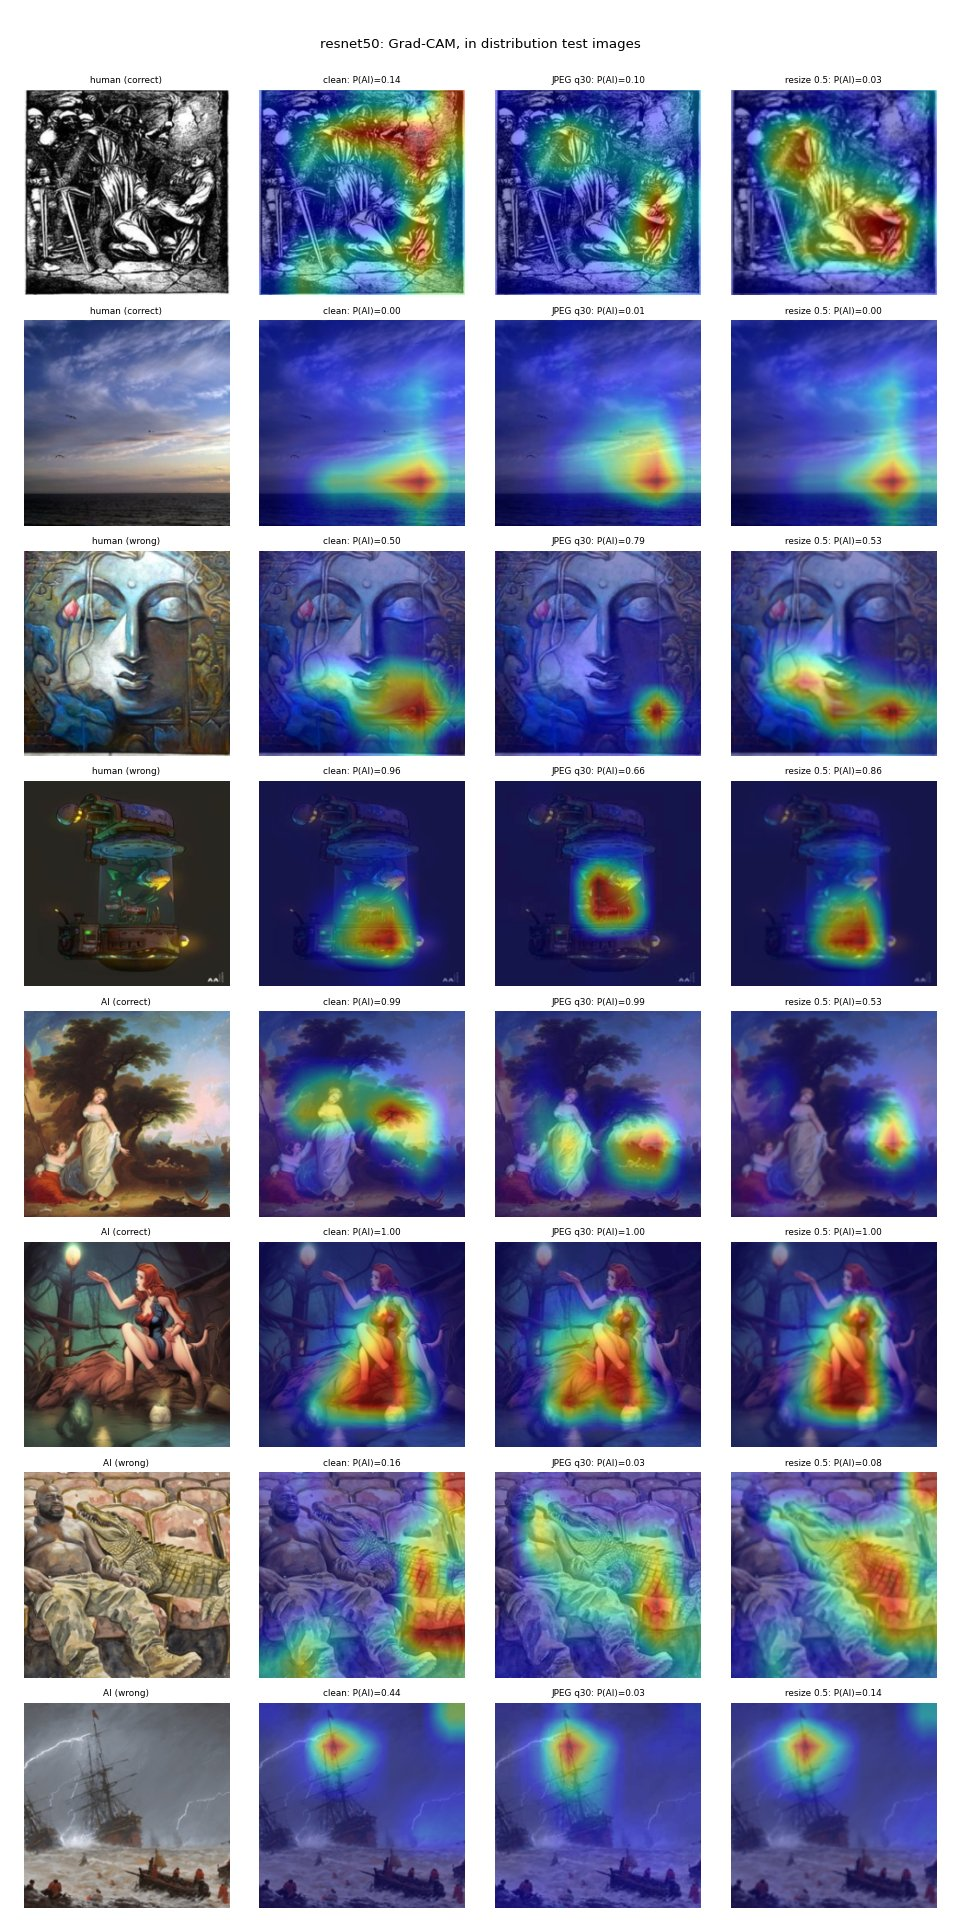

resnet50 examples_external


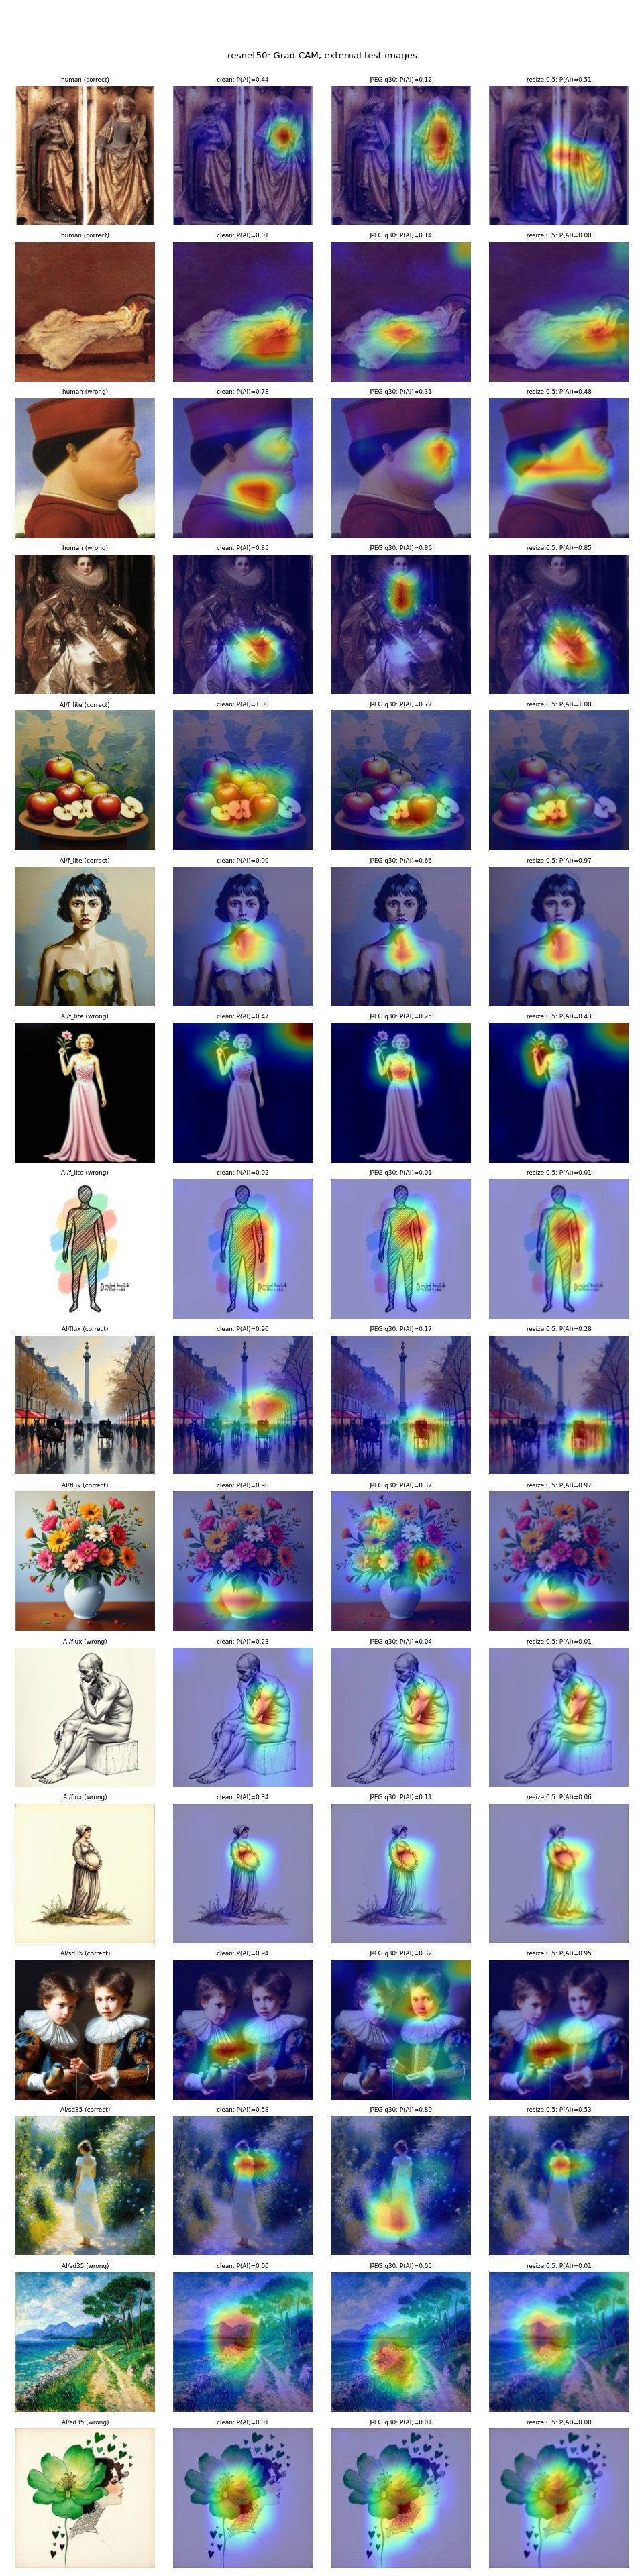

resnet50 watermark


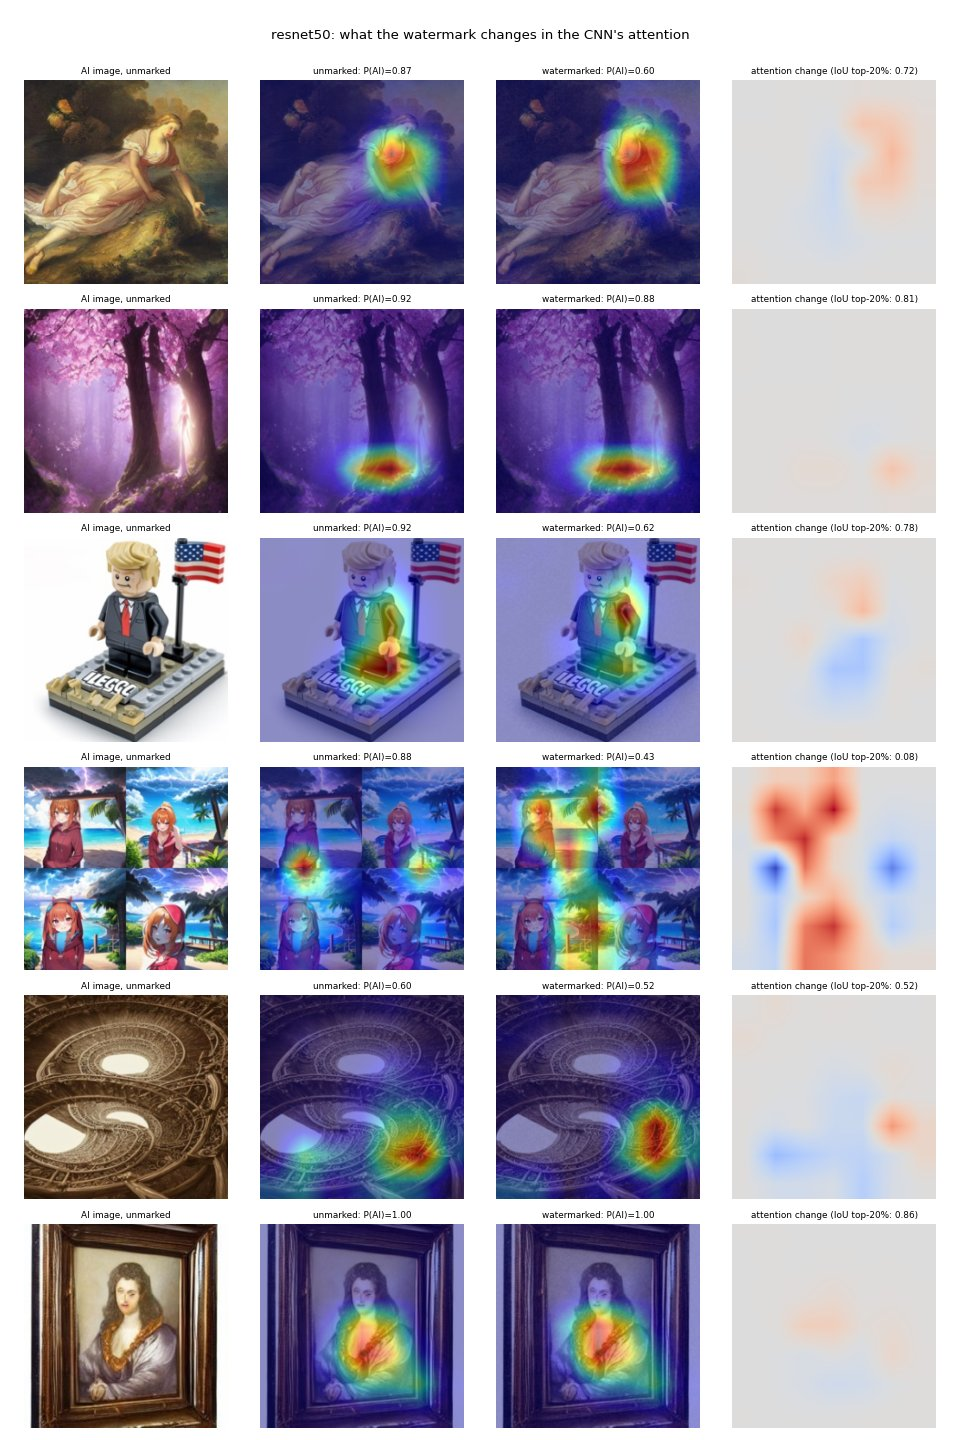

resnet50: attention stability (IoU of top-20% region with the clean heatmap) and prediction flips


set                     external        in_distribution       
class                         ai  human              ai  human
comparison                                                    
clean vs jpeg_q30          0.417  0.428           0.540  0.526
clean vs jpeg_q50          0.460  0.496           0.572  0.583
clean vs jpeg_q70          0.522  0.552           0.639  0.672
clean vs jpeg_q90          0.685  0.640           0.767  0.751
clean vs recompress_x3     0.527  0.597           0.652  0.703
clean vs resize_0.25       0.413  0.476           0.434  0.522
clean vs resize_0.5        0.624  0.592           0.634  0.670
clean vs webp_q80          0.659  0.670           0.723  0.744
unmarked vs watermarked    0.571    NaN           0.611    NaN

set                     external        in_distribution       
class                         ai  human              ai  human
comparison                                                    
clean vs jpeg_q30          0.363  0.183           0.263  0.147
clean vs jpeg_q50          0.323  0.097           0.240  0.107
clean vs jpeg_q70          0.230  0.083           0.190  0.053
clean vs jpeg_q90          0.090  0.050           0.080  0.053
clean vs recompress_x3     0.240  0.050           0.180  0.047
clean vs resize_0.25       0.407  0.027           0.473  0.053
clean vs resize_0.5        0.140  0.030           0.163  0.030
clean vs webp_q80          0.130  0.027           0.113  0.030
unmarked vs watermarked    0.187    NaN           0.200    NaN

efficientnet_b0 examples_in_distribution


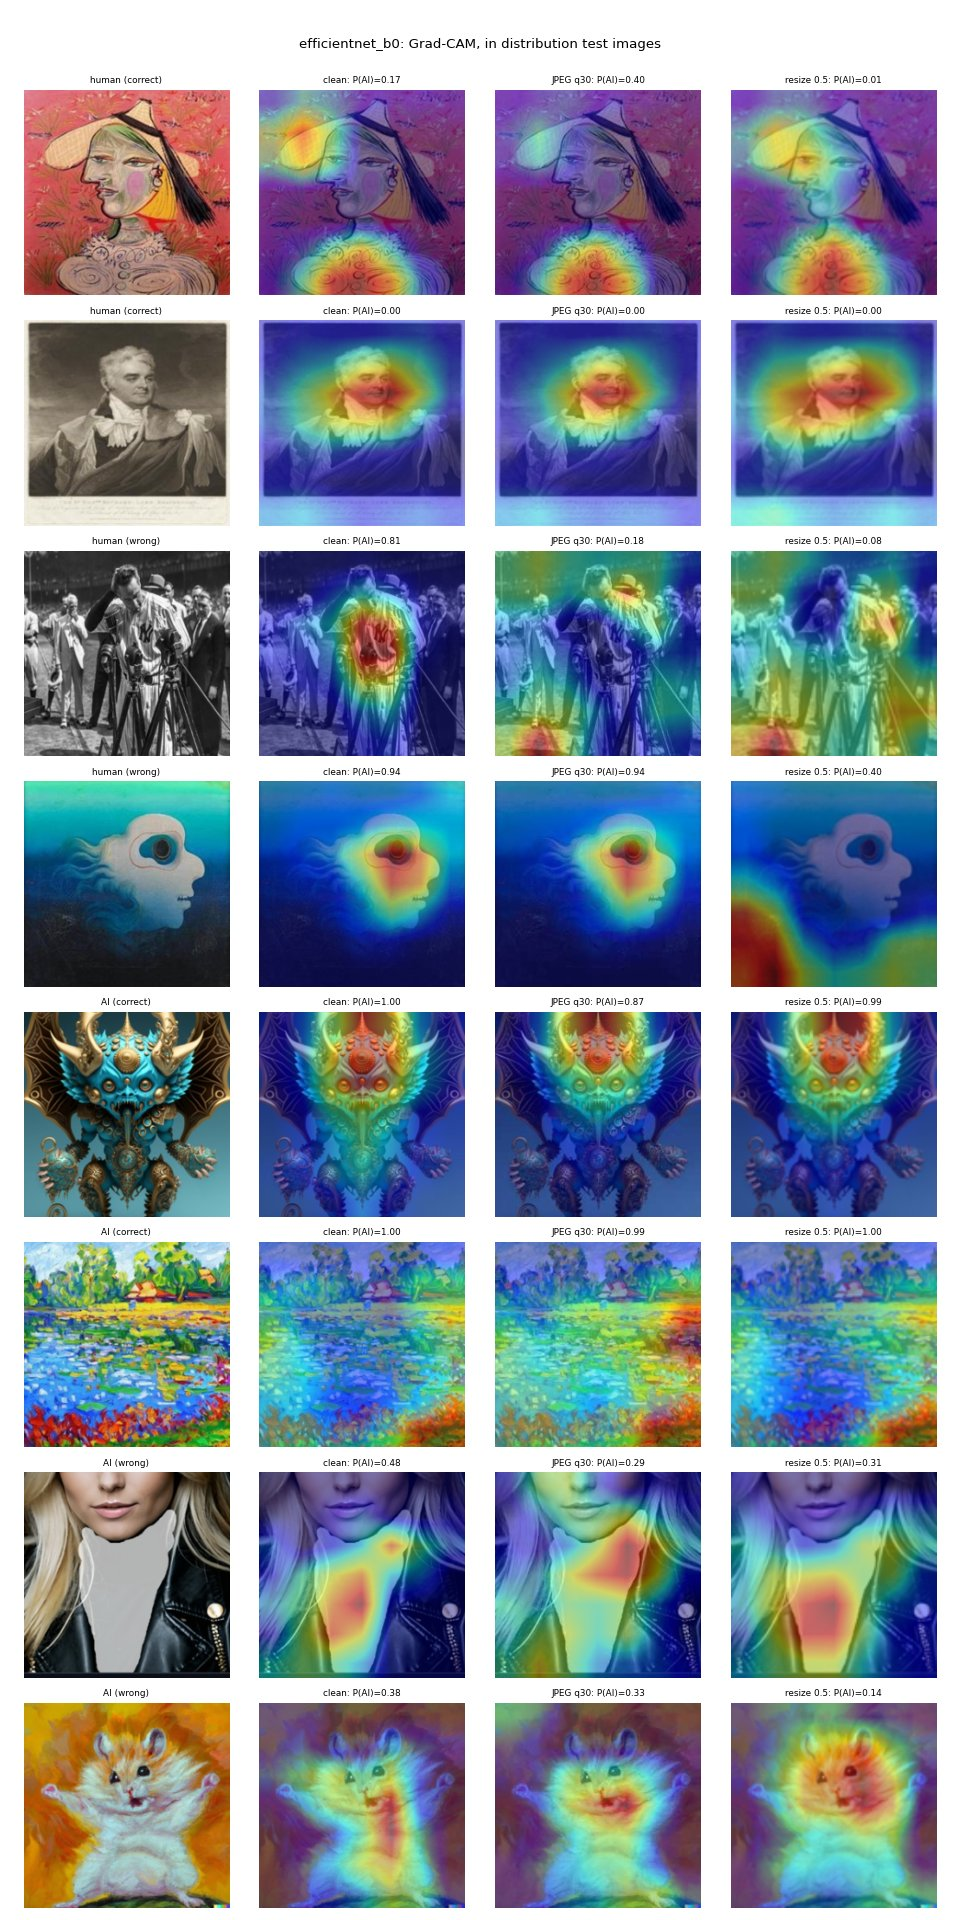

efficientnet_b0 examples_external


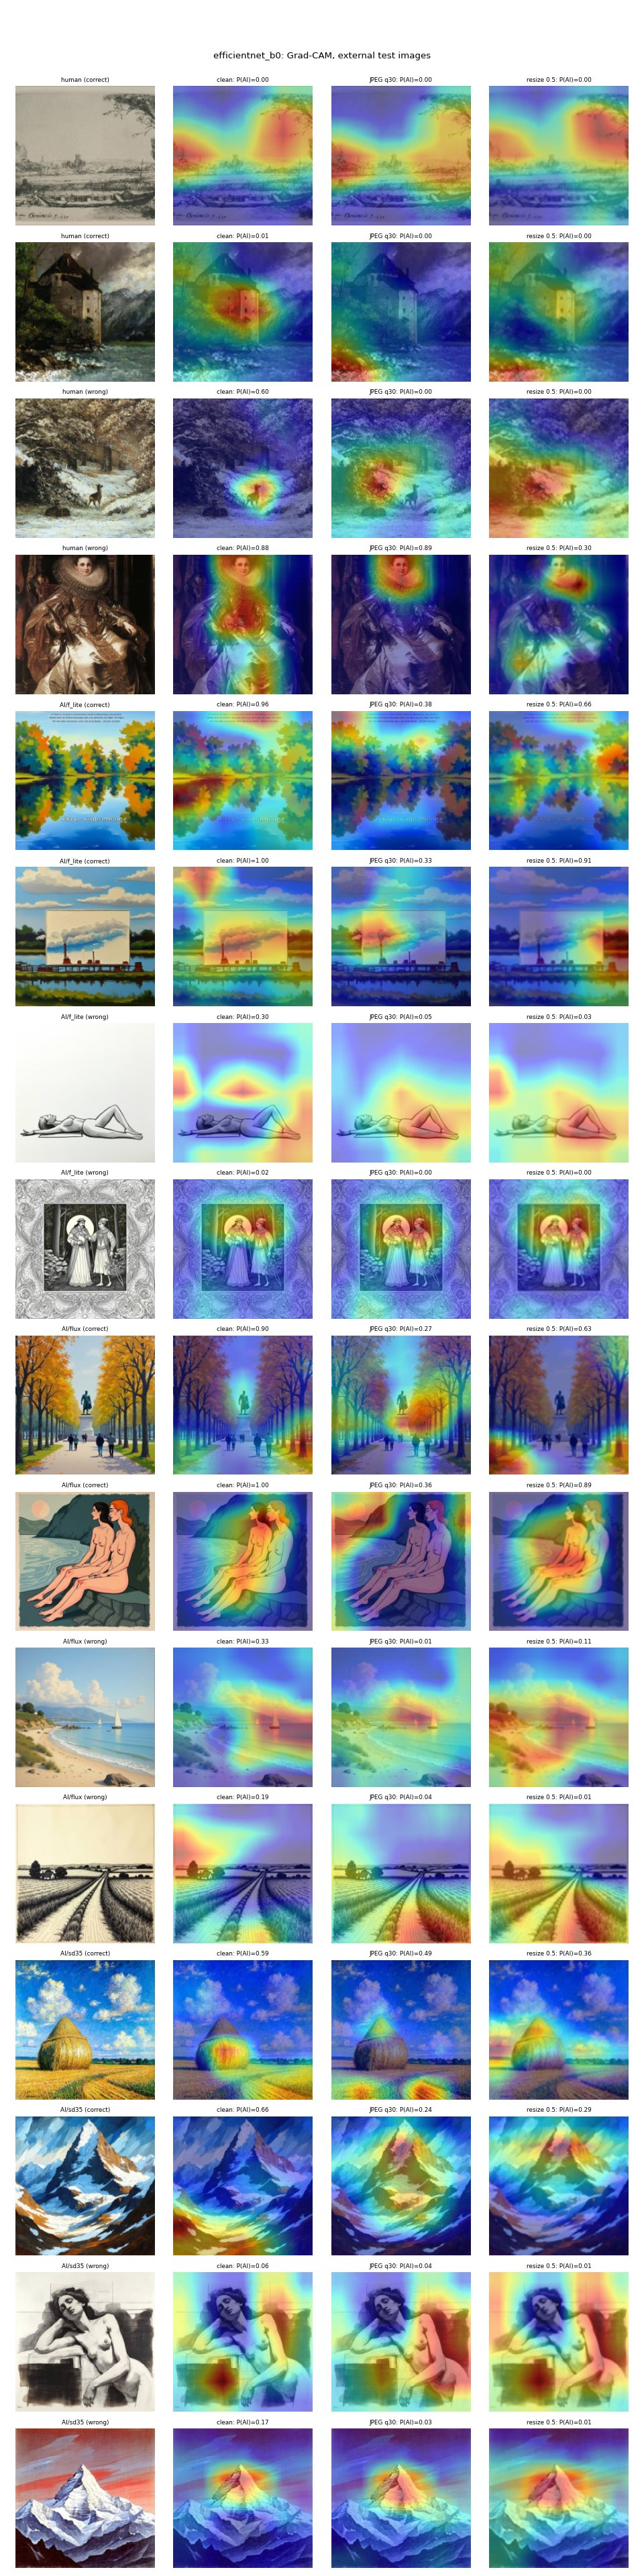

efficientnet_b0 watermark


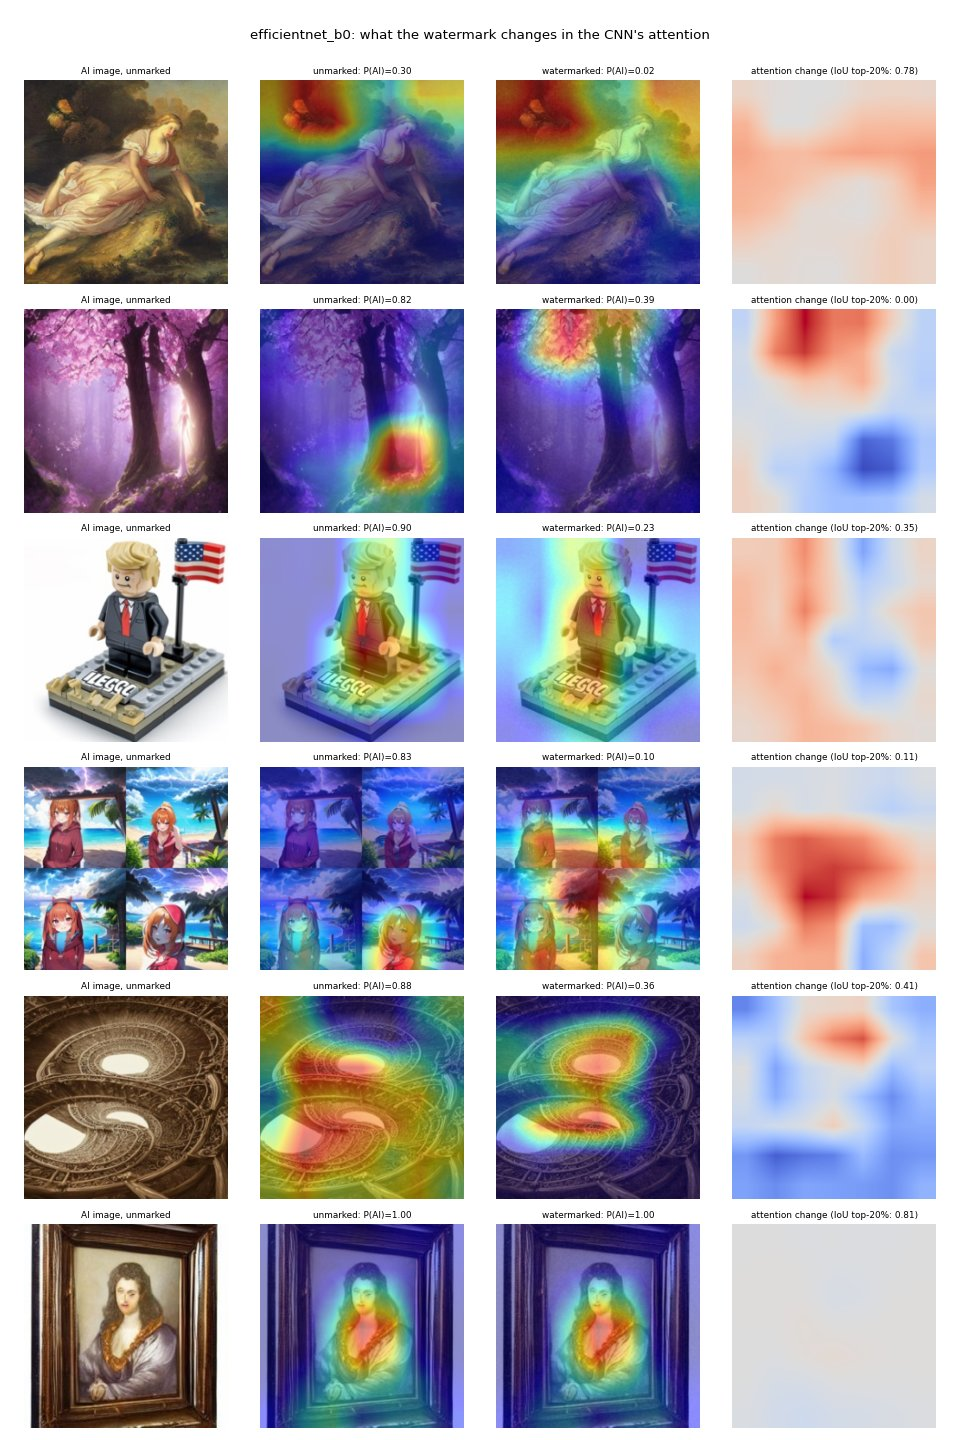

efficientnet_b0: attention stability (IoU of top-20% region with the clean heatmap) and prediction flips


set                     external        in_distribution       
class                         ai  human              ai  human
comparison                                                    
clean vs jpeg_q30          0.306  0.467           0.483  0.552
clean vs jpeg_q50          0.383  0.523           0.537  0.608
clean vs jpeg_q70          0.498  0.596           0.646  0.699
clean vs jpeg_q90          0.728  0.726           0.781  0.790
clean vs recompress_x3     0.500  0.627           0.662  0.723
clean vs resize_0.25       0.167  0.383           0.225  0.427
clean vs resize_0.5        0.471  0.539           0.491  0.622
clean vs webp_q80          0.670  0.686           0.712  0.713
unmarked vs watermarked    0.331    NaN           0.476    NaN

set                     external        in_distribution       
class                         ai  human              ai  human
comparison                                                    
clean vs jpeg_q30          0.443  0.050           0.253  0.057
clean vs jpeg_q50          0.370  0.043           0.187  0.057
clean vs jpeg_q70          0.247  0.027           0.117  0.037
clean vs jpeg_q90          0.070  0.017           0.040  0.027
clean vs recompress_x3     0.263  0.023           0.120  0.040
clean vs resize_0.25       0.710  0.020           0.637  0.060
clean vs resize_0.5        0.277  0.020           0.243  0.047
clean vs webp_q80          0.120  0.013           0.083  0.033
unmarked vs watermarked    0.437    NaN           0.303    NaN

In [9]:
import io
from PIL import Image as PILImage
from IPython.display import Image as Show, display as show


def preview(path, quality=85):
    """The figure re-encoded as JPEG for display, so the saved notebook stays small enough
    for File > Save a copy in GitHub. The full-quality PNG in outputs/gradcam/ is unchanged."""
    buf = io.BytesIO()
    PILImage.open(path).convert("RGB").save(buf, "JPEG", quality=quality)
    return Show(data=buf.getvalue(), format="jpeg", width=900)


for arch in ARCHS:
    for name in ["examples_in_distribution", "examples_external", "watermark"]:
        print(arch, name)
        show(preview(f"outputs/gradcam/{arch}/{name}.png"))
    s = pd.read_csv(f"outputs/gradcam/{arch}/stability.csv")
    print(f"{arch}: attention stability (IoU of top-20% region with the clean heatmap) and prediction flips")
    display(s.pivot_table(index="comparison", columns=["set", "class"], values="iou_top20_mean").round(3))
    display(s.pivot_table(index="comparison", columns=["set", "class"], values="prediction_flip_rate").round(3))

## 7. Save it
File > Save a copy in GitHub. Results are on Drive (`thesis-data/evaluation/external/`, `thesis-data/gradcam/`) and are collected by notebook 06.